In [1]:
# Librerías necesarias 
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

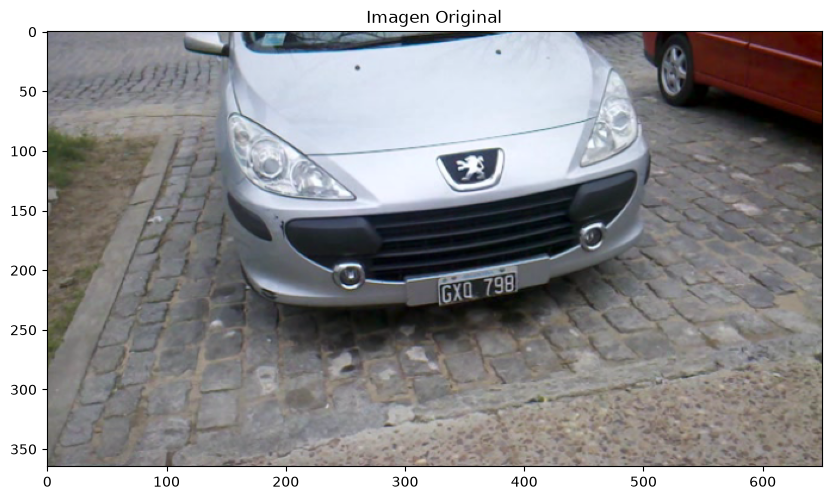

In [27]:
# Cargamos la imagen original
imagen_orig = cv2.imread('./img02.png')

# Redimensionar a un ancho fijo de 600px para normalizar métricas de área
valor_w = 650
h_orig, w_orig = imagen_orig.shape[:2]
escala = valor_w / float(w_orig)
target_h = int(h_orig * escala)
imagen = cv2.resize(imagen_orig, (valor_w, target_h))

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title('Imagen Original')
#plt.axis('off')
plt.show()


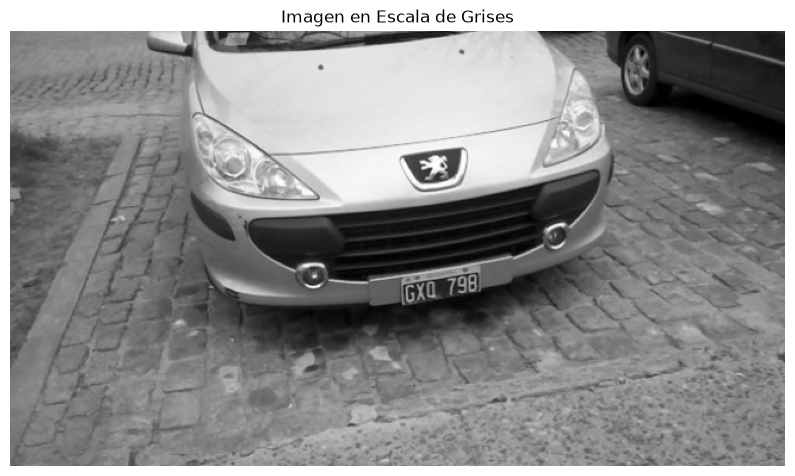

In [28]:
# Convertimos a escala de grises
imagen_gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 10))
plt.imshow(imagen_gris, cmap='gray')
plt.title('Imagen en Escala de Grises')
plt.axis('off')
plt.show()



In [29]:
# Umbralamos para aislar la patente en negro/blanco
_, imagen_binaria = cv2.threshold(imagen_gris, 100, 255, cv2.THRESH_BINARY)
"""
plt.figure(figsize=(10, 10))
plt.imshow(imagen_binaria, cmap='gray')
plt.title('Imagen Binaria')
#plt.axis('off')
plt.show()
"""

"\nplt.figure(figsize=(10, 10))\nplt.imshow(imagen_binaria, cmap='gray')\nplt.title('Imagen Binaria')\n#plt.axis('off')\nplt.show()\n"

97
Etiqueta 58: Área 63 Bbox -> Base: 8 Altura:15
Etiqueta 60: Área 38 Bbox -> Base: 7 Altura:15
Etiqueta 61: Área 62 Bbox -> Base: 7 Altura:14
Etiqueta 68: Área 60 Bbox -> Base: 7 Altura:14
Etiqueta 71: Área 59 Bbox -> Base: 7 Altura:15
Etiqueta 72: Área 48 Bbox -> Base: 7 Altura:14


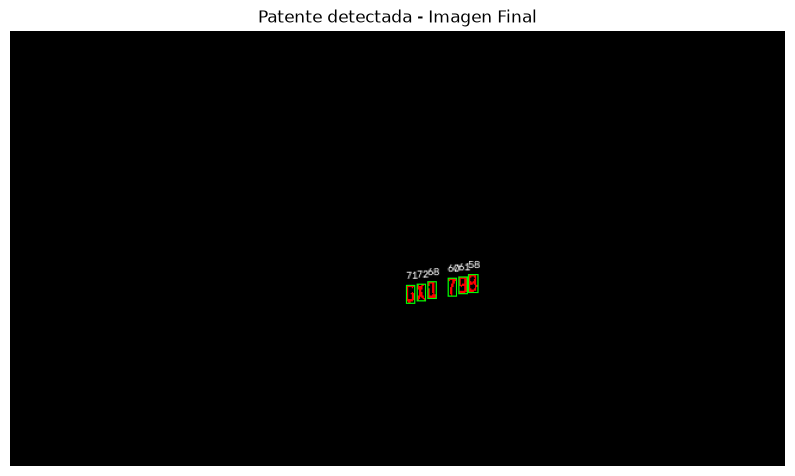

In [30]:
# Aplicamos componentes conectadas
# Filtramos las etiquetas con Area mayor a 25 y menor a 80
num_etiquetas, etiquetas, stats, _ = cv2.connectedComponentsWithStats(imagen_binaria, connectivity=8)

# Crear una imagen negra en formato RGB (alto, ancho, 3 canales)
alto, ancho = etiquetas.shape
im_final = np.zeros((alto, ancho, 3), dtype=np.uint8)

print(num_etiquetas)

for i in range(1, num_etiquetas):
    x, y, w, h, area = stats[i]
    # Filtramos por área y relación de aspecto
    if area > 25 and area < 80:
        if h/w > 1.5 and h/w < 2.2:
            # Pintar el objeto de color ROJO puro en formato RGB: [R=255, G=0, B=0]
            im_final[etiquetas == i] = [255, 0, 0]

            # Bounding box color verde (0, 255, 0) con grosor fino 1
            cv2.rectangle(im_final, (x, y), (x + w, y + h), (0, 255, 0), 1)
            # Texto/Etiquetas color rojo (0, 0, 255) en formato BGR
            cv2.putText(im_final, str(i), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 255, 255), 1)
            print(f"Etiqueta {i}: Área {area} Bbox -> Base: {w} Altura:{h}")

# Mostramos únicamente la imagen final con todas las detecciones aplicadas
plt.figure(figsize=(10, 10))
plt.imshow(im_final)
plt.title('Patente detectada - Imagen Final')
plt.axis('off')
plt.show()